In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
# import lightgbm as lgb
from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# 1. Dataset loading and splitting

In [166]:
data = pd.read_csv("electricity_practice.csv")
# data = data.rename(columns={"A": "new_A", "B": "new_B"})
data = data.drop_duplicates(subset = ["time"])
data["time"] = pd.to_datetime(data["time"])
data = data.set_index("time").sort_index().asfreq("h")

train, test = train_test_split(data, test_size = 0.2, shuffle = False)

display(train.head())
display(test.head())

,Thermal_Methane,Wind_Offshore,Thermal_Coal_Derived_Gas,Waste,Other_Renewables,Other_Generation,Pumped_Storage,Thermal_Oil,Thermal_Oil_Shale,Thermal_Lignite,Thermal_Peat,Solar,Wind_Onshore,Nuclear,Thermal_Hard_Coal,Hydro_Run_of_River,Hydro_Reservoir,Thermal_Biomass,Marine,Geothermal
time,,,,,,,,,,,,,,,,,,,,
2015-01-01 00:00:00+00:00,0.000,1607.587,0.0,0.0,10.0,20.0,0.0,0.0,0.0,376.417,0.0,0.0,12087.894,5015.564,2122.419,868.592,NaN,1720.416,0.0,2.008
2015-01-01 01:00:00+00:00,0.000,1579.657,0.0,0.0,10.0,20.0,0.0,0.0,0.0,389.301,0.0,0.0,12049.411,5029.224,2409.131,870.949,NaN,1710.287,0.0,1.834
2015-01-01 02:00:00+00:00,0.000,1433.896,0.0,0.0,10.0,20.0,0.0,0.0,0.0,391.268,0.0,0.0,11446.916,5030.350,2806.308,884.789,NaN,1701.422,0.0,1.586
2015-01-01 03:00:00+00:00,0.000,1402.544,0.0,0.0,10.0,20.0,0.0,0.0,0.0,399.434,0.0,0.0,10464.707,5039.943,3492.091,882.526,NaN,1699.186,0.0,1.379
2015-01-01 04:00:00+00:00,19.055,1387.978,0.0,0.0,10.0,20.0,0.0,0.0,0.0,401.243,0.0,0.0,10420.088,5022.995,3621.176,869.077,NaN,1695.605,0.0,1.657


,Thermal_Methane,Wind_Offshore,Thermal_Coal_Derived_Gas,Waste,Other_Renewables,Other_Generation,Pumped_Storage,Thermal_Oil,Thermal_Oil_Shale,Thermal_Lignite,Thermal_Peat,Solar,Wind_Onshore,Nuclear,Thermal_Hard_Coal,Hydro_Run_of_River,Hydro_Reservoir,Thermal_Biomass,Marine,Geothermal
time,,,,,,,,,,,,,,,,,,,,
2022-03-14 14:00:00+00:00,721.753,4456.281,NaN,151.376,10.0,20.0,0.000,0.0,NaN,NaN,NaN,3398.861,12782.759,4001.666,1067.244,1348.169,8.511,1860.184,NaN,17.595
2022-03-14 15:00:00+00:00,596.784,5108.760,NaN,144.687,10.0,20.0,52.488,0.0,NaN,3.177,NaN,1968.645,14001.707,4010.807,1022.792,1338.900,10.580,1867.491,NaN,17.881
2022-03-14 16:00:00+00:00,855.743,4675.293,NaN,149.093,10.0,20.0,139.861,0.0,NaN,3.295,NaN,844.894,14194.932,4010.366,1135.029,1339.646,7.304,1899.141,NaN,17.747
2022-03-14 17:00:00+00:00,1146.163,4685.849,NaN,190.390,10.0,20.0,309.019,0.0,NaN,3.645,NaN,101.623,13863.471,4002.470,1136.083,1341.445,7.301,1894.949,NaN,17.484
2022-03-14 18:00:00+00:00,1564.421,5164.705,NaN,200.548,10.0,20.0,509.133,0.0,NaN,3.568,NaN,0.000,10618.480,4000.893,NaN,1359.973,7.828,1887.621,NaN,17.077


# 2. Inspect data quality

In [167]:
train.info()
train.describe()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 63110 entries, 2015-01-01 00:00:00+00:00 to 2022-03-14 13:00:00+00:00
Freq: h
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Thermal_Methane           62445 non-null  float64
 1   Wind_Offshore             62515 non-null  float64
 2   Thermal_Coal_Derived_Gas  20020 non-null  float64
 3   Waste                     62260 non-null  float64
 4   Other_Renewables          62067 non-null  float64
 5   Other_Generation          62562 non-null  float64
 6   Pumped_Storage            62433 non-null  float64
 7   Thermal_Oil               62446 non-null  float64
 8   Thermal_Oil_Shale         19678 non-null  float64
 9   Thermal_Lignite           62171 non-null  float64
 10  Thermal_Peat              19852 non-null  float64
 11  Solar                     62466 non-null  float64
 12  Wind_Onshore              61929 non-null  float64
 13  Nuclea

,Thermal_Methane,Wind_Offshore,Thermal_Coal_Derived_Gas,Waste,Other_Renewables,Other_Generation,Pumped_Storage,Thermal_Oil,Thermal_Oil_Shale,Thermal_Lignite,Thermal_Peat,Solar,Wind_Onshore,Nuclear,Thermal_Hard_Coal,Hydro_Run_of_River,Hydro_Reservoir,Thermal_Biomass,Marine,Geothermal
count,62445.000000,62515.000000,20020.0,62260.000000,62067.000000,62562.000000,62433.000000,62446.000000,19678.0,62171.000000,19852.0,62466.000000,61929.000000,62278.000000,62311.000000,62385.000000,62180.000000,62472.000000,19877.0,62346.000000
mean,1247.930069,1912.385953,0.0,160.502402,9.655453,36.777277,158.738276,22.602327,0.0,73.994653,0.0,2018.190086,5782.459025,3798.244414,1879.646561,951.510455,33.030255,1966.593138,0.0,11.851659
std,757.681391,1489.075938,0.0,125.511342,0.861781,39.548052,216.741164,122.938968,0.0,134.149334,0.0,3012.396498,4618.398480,521.371849,1320.822022,263.128410,36.256220,194.981122,0.0,8.613924
min,-23.736000,-9.978000,0.0,-9.878000,7.500000,20.000000,0.000000,-24.910000,0.0,-14.173000,0.0,-130.073000,3.538000,-163.254000,-56.949000,-26.846000,-1.000000,-71.364000,0.0,-1.000000
25%,675.338000,641.191000,0.0,45.848750,10.000000,20.000000,0.000000,0.000000,0.0,2.527500,0.0,0.000000,1740.392000,3832.527000,794.518000,758.718000,14.302500,1792.820750,0.0,3.000000
50%,1226.584000,1600.116000,0.0,154.800000,10.000000,20.000000,44.468000,0.000000,0.0,9.181000,0.0,0.000000,4552.856000,3929.399000,1620.432000,941.412000,25.152500,1949.374000,0.0,12.052000
75%,1780.121000,2882.451000,0.0,272.861500,10.000000,20.000000,265.290000,0.000000,0.0,32.137000,0.0,3408.049000,9360.578000,4000.797750,2675.956500,1122.131000,37.180250,2144.766750,0.0,19.146000
max,4873.214000,16234.902000,0.0,1177.771000,10.000000,130.000000,1397.173000,1500.000000,0.0,508.674000,0.0,30321.364000,105393.869000,22754.163000,6770.213000,5077.283000,280.866000,7389.063000,0.0,81.326000


### check missing pattern

In [168]:
summary = {}

for col in train.columns:
    missing = train[col].isna()
    groups = train[col].notna().cumsum()
    gaps = missing.groupby(groups).sum()
    gaps = gaps[gaps > 0]

    first_valid = train[col].first_valid_index()
    dates = (
        train.index[missing & (groups == gaps.idxmax())]
        if len(gaps) else []
    )

    summary[col] = {
        "leading_hours": train.index.get_loc(first_valid)
                         if first_valid is not None else len(train),
        "number_of_gaps": len(gaps),
        "longest_gap": gaps.max() if len(gaps) else 0,
        "average_gap": gaps.mean() if len(gaps) else 0,
        "longest_start": dates[0] if len(dates) else pd.NaT,
        "longest_end": dates[-1] if len(dates) else pd.NaT
    }

gap_summary = pd.DataFrame(summary.values(), index=summary.keys()).round(2)
display(gap_summary)

,leading_hours,number_of_gaps,longest_gap,average_gap,longest_start,longest_end
Thermal_Methane,0,287,120,2.32,2021-01-16 02:00:00+00:00,2021-01-21 01:00:00+00:00
Wind_Offshore,0,359,48,1.66,2016-04-01 07:00:00+00:00,2016-04-03 06:00:00+00:00
Thermal_Coal_Derived_Gas,0,148,42686,291.15,2017-05-01 00:00:00+00:00,2022-03-14 13:00:00+00:00
Waste,0,569,120,1.49,2016-10-30 20:00:00+00:00,2016-11-04 19:00:00+00:00
Other_Renewables,0,606,120,1.72,2015-12-04 14:00:00+00:00,2015-12-09 13:00:00+00:00
Other_Generation,0,277,120,1.98,2021-12-29 02:00:00+00:00,2022-01-03 01:00:00+00:00
Pumped_Storage,0,392,120,1.73,2016-02-18 18:00:00+00:00,2016-02-23 17:00:00+00:00
Thermal_Oil,0,456,72,1.46,2021-07-10 09:00:00+00:00,2021-07-13 08:00:00+00:00
Thermal_Oil_Shale,0,165,42686,263.22,2017-05-01 00:00:00+00:00,2022-03-14 13:00:00+00:00
Thermal_Lignite,0,666,120,1.41,2016-07-31 18:00:00+00:00,2016-08-05 17:00:00+00:00


In [169]:
# Remove the 480-hour opening missing block
train = train.iloc[480:].copy()

print("New training start:", train.index[0])
print("Remaining training rows:", len(train))

New training start: 2015-01-21 00:00:00+00:00
Remaining training rows: 62630


## 2.1 Clean anomalies and invalid values

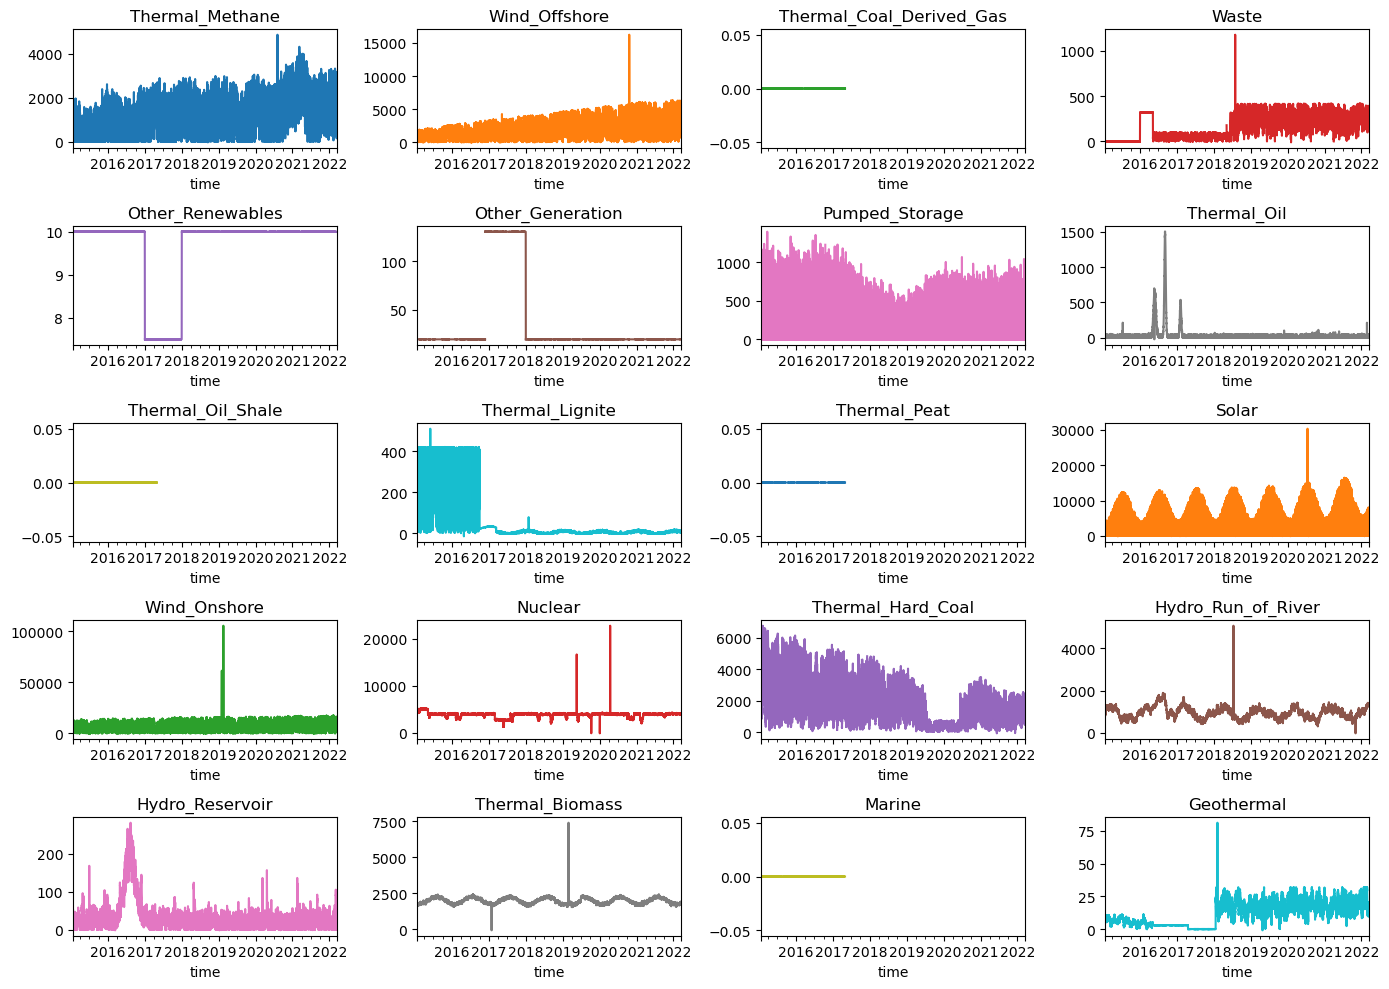

In [170]:
train.plot.line(
    subplots=True,
    sharex=False,
    layout=(5,4),
    figsize=(14,10),
    legend=False,
    title=list(train.columns)
)
plt.tight_layout()
plt.show()

In [171]:
# # Apply fixed cutoff to clean out obvious extreme high values
# cutoffs = {
#     "Thermal_Methane": 4500,
#     "Waste": 1000,
#     "Thermal_Lignite": 480,
#     "Solar": 20000,
#     "Wind_Onshore": 25000,
#     "Wind_Offshore": 10000,
#     "Nuclear": 10000,
#     "Hydro_Run_of_River": 2500,
#     "Thermal_Biomass": 6000,
#     "Thermal_Hard_Coal": 7000,
#     "Geothermal": 50,
# }

# # Sources with only zeros 
# zero_cols = ["Thermal_Coal_Derived_Gas", 'Thermal_Oil_Shale', 'Thermal_Peat', 'Marine']
# # Sources with nearly constant values
# const_cols = ["Other_Generation", "Other_Renewables"]

# def clean_anomalies(df):
#     cleaned = df.copy()

#     # Mask obvious anomalies
#     for column, cutoff in cutoffs.items():
#         cleaned[column] = cleaned[column].mask(cleaned[column] > cutoff)

#     # Mask invalid negative generation 
#     cleaned = cleaned.mask(cleaned < 0)

#     return cleaned.drop(columns = zero_cols + const_cols)

# train_clean = clean_anomalies(train)
# test_clean = clean_anomalies(test)

In [172]:
# Zero-only and nearly constant columns
inactive_cols = [
    "Thermal_Coal_Derived_Gas", "Thermal_Oil_Shale",
    "Thermal_Peat", "Marine", "Other_Generation", "Other_Renewables"
]

train_clean = train.drop(columns=inactive_cols)
test_clean = test.drop(columns=inactive_cols)

### Check invalid/outliers

In [173]:
# Count negative values per column
display((train_clean < 0).sum().rename("negative_count"))

# Inspect the largest hourly changes
changes = train_clean.diff()

for col in train_clean.columns:
    largest = changes[col].abs().nlargest(5).index

    print(col)
    display(pd.DataFrame({
        "previous": train_clean[col].shift(1),
        "current": train_clean[col],
        "change": changes[col]
    }).loc[largest])

Thermal_Methane       1
Wind_Offshore         0
Waste                 1
Pumped_Storage        0
Thermal_Oil           2
Thermal_Lignite       2
Solar                 1
Wind_Onshore          0
Nuclear               2
Thermal_Hard_Coal     2
Hydro_Run_of_River    1
Hydro_Reservoir       2
Thermal_Biomass       1
Geothermal            1
Name: negative_count, dtype: int64

Thermal_Methane


,previous,current,change
time,,,
2020-08-05 09:00:00+00:00,4873.214,727.301,-4145.913
2020-08-05 08:00:00+00:00,831.039,4873.214,4042.175
2017-01-11 12:00:00+00:00,1131.527,80.911,-1050.616
2022-02-19 00:00:00+00:00,3032.836,2038.409,-994.427
2022-01-29 00:00:00+00:00,2210.316,1225.880,-984.436


Wind_Offshore


,previous,current,change
time,,,
2020-10-20 23:00:00+00:00,2757.007,16234.902,13477.895
2020-10-21 00:00:00+00:00,16234.902,3082.876,-13152.026
2017-05-10 16:00:00+00:00,4270.877,1042.632,-3228.245
2017-05-10 15:00:00+00:00,1223.959,4270.877,3046.918
2022-02-18 11:00:00+00:00,4217.676,2329.725,-1887.951


Waste


... (19 outputs left out)

Thermal_Biomass


,previous,current,change
time,,,
2019-02-28 09:00:00+00:00,7389.063,1743.533,-5645.530
2019-02-28 08:00:00+00:00,1743.931,7389.063,5645.132
2017-01-27 22:00:00+00:00,-71.364,1801.092,1872.456
2017-01-27 21:00:00+00:00,1762.585,-71.364,-1833.949
2019-07-01 00:00:00+00:00,1972.025,2222.810,250.785


Geothermal


,previous,current,change
time,,,
2018-02-05 22:00:00+00:00,81.326,15.889,-65.437
2018-02-05 21:00:00+00:00,15.891,81.326,65.435
2019-04-27 19:00:00+00:00,24.854,-1.000,-25.854
2019-04-27 20:00:00+00:00,-1.000,23.877,24.877
2018-01-19 01:00:00+00:00,0.000,21.004,21.004


In [174]:
# Check autocorr of different sources for forward filling
for col in train_clean:
    cutoff = 0

    for lag in range(1, 25):
        if train_clean[col].autocorr(lag) >= 0.95:
            cutoff = lag
        else:
            break

    print(f"{col}: {cutoff} hours")

Thermal_Methane: 1 hours
Wind_Offshore: 3 hours
Waste: 12 hours
Pumped_Storage: 0 hours
Thermal_Oil: 24 hours
Thermal_Lignite: 4 hours
Solar: 0 hours
Wind_Onshore: 1 hours
Nuclear: 18 hours
Thermal_Hard_Coal: 3 hours
Hydro_Run_of_River: 24 hours
Hydro_Reservoir: 15 hours
Thermal_Biomass: 24 hours
Geothermal: 24 hours


# Part 1

## Q1: Source trend, seasonality, data issue

Use cleaned development data only. Daily averages reveal the long-run movements, while monthly and hourly averages show recurring seasonality.

### a: Trend analysis

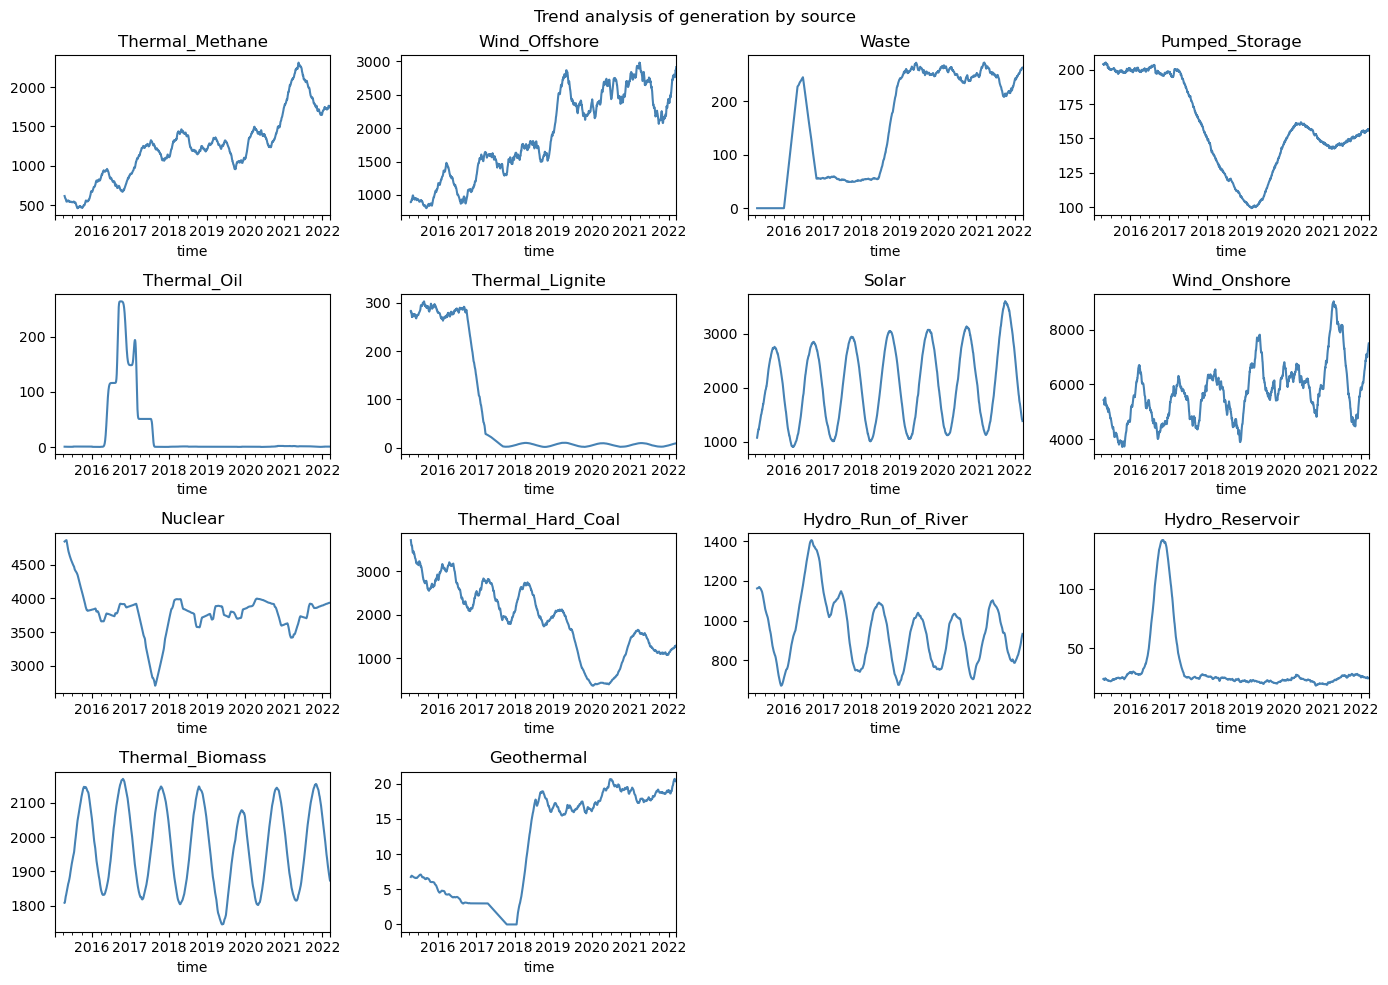

In [175]:
daily_sources = train_clean.resample("D").mean()
daily_counts = train_clean.resample("D").count()

daily_sources = daily_sources.where(daily_counts >= 12)

trend = daily_sources.rolling(180, min_periods = 90).mean()
trend.plot.line(
    subplots=True,
    sharex=False,
    layout=(4,4),
    figsize=(14,10),
    legend=False,
    title=list(train_clean.columns),
    color="steelblue"
)
plt.suptitle("Trend analysis of generation by source")
plt.tight_layout()
plt.show()


### b: Annual and intraday seasonality

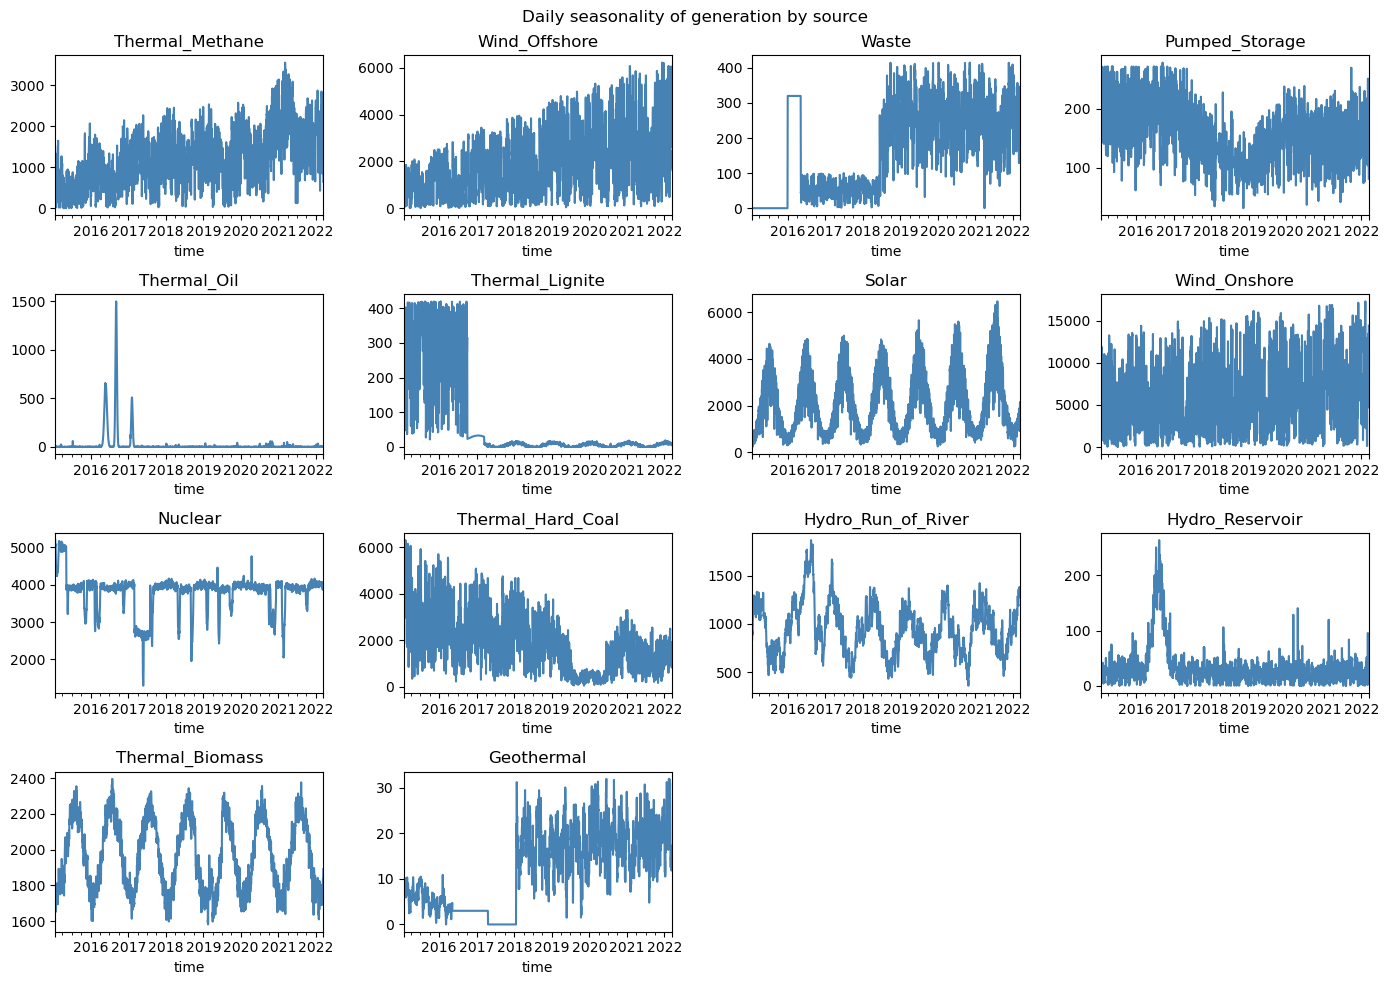

In [176]:
daily_sources.plot.line(
    subplots=True,
    sharex=False,
    layout=(4,4),
    figsize=(14,10),
    legend=False,
    title=list(train_clean.columns),
    color="steelblue"
)
plt.suptitle("Daily seasonality of generation by source")
plt.tight_layout()
plt.show()

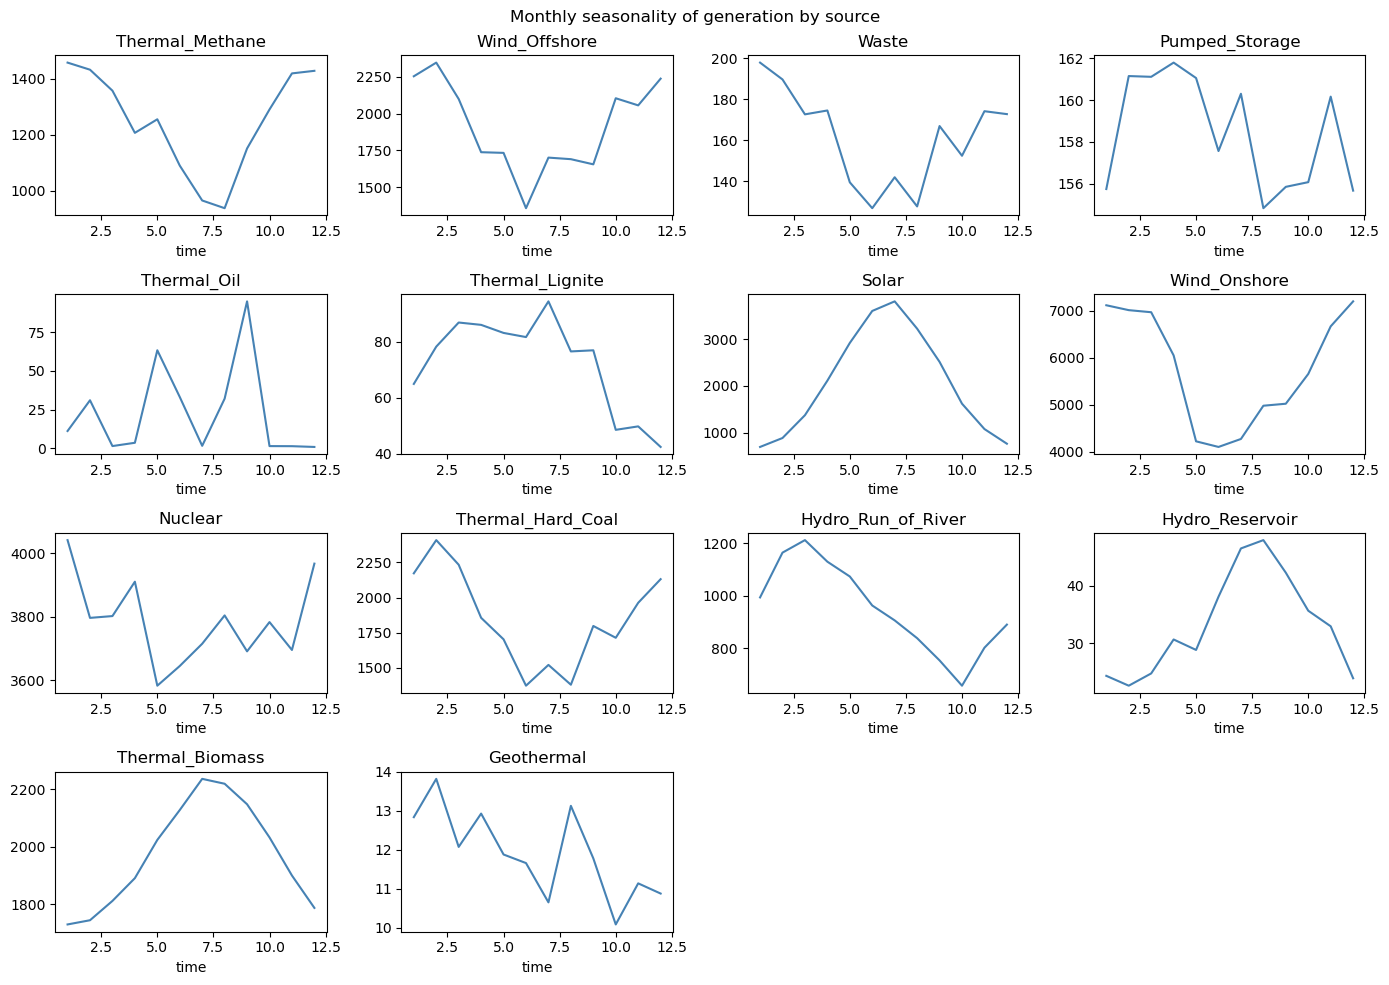

In [177]:
# Monthly seasonality
monthly_sources = train_clean.groupby(train_clean.index.month).mean()

monthly_sources.plot.line(
    subplots=True,
    sharex=False,
    layout=(4,4),
    figsize=(14,10),
    legend=False,
    title=list(train_clean.columns),
    color="steelblue"
)
plt.suptitle("Monthly seasonality of generation by source")
plt.tight_layout()
plt.show()

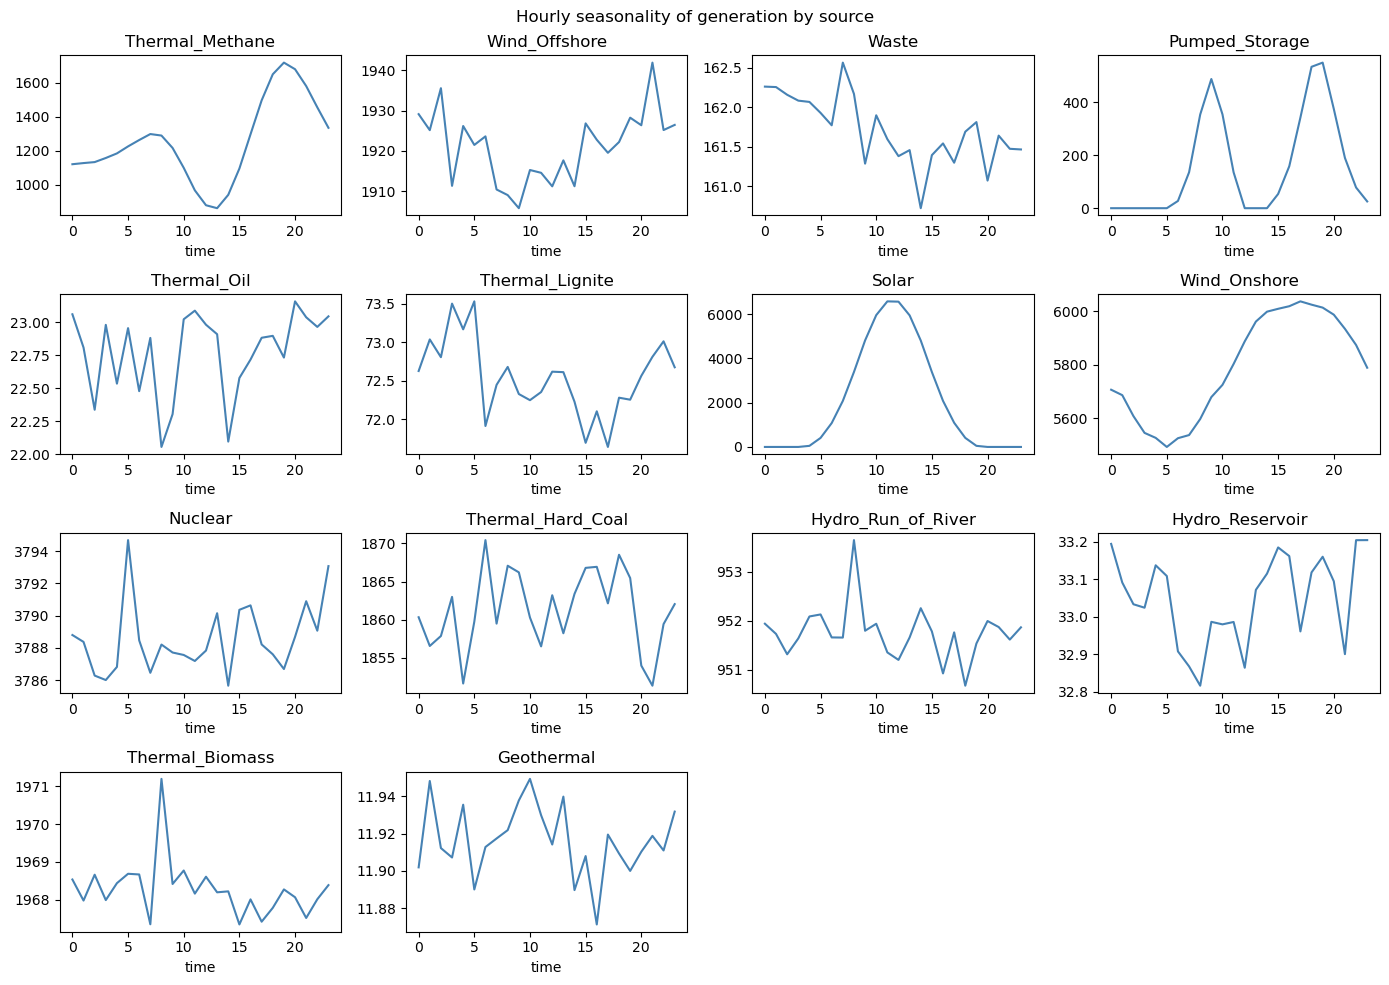

In [178]:
# Intraday seasonality
hourly_sources = train_clean.groupby(train_clean.index.hour).mean()

hourly_sources.plot.line(
    subplots=True,
    sharex=False,
    layout=(4,4),
    figsize=(14,10),
    legend=False,
    title=list(train_clean.columns),
    color="steelblue"
)
plt.suptitle("Hourly seasonality of generation by source")
plt.tight_layout()
plt.show()

### Q1 finding summary

**1. Long-Term Trends**

Different generation sources exhibit distinct long-term trends.

- **Wind**, **Solar**, **Thermal**, **Nuclear** 
  
**2. Annual Seasonality**

Several generation sources exhibit clear seasonal patterns.

- **Solar**, **Hydro**, **Thermal Biomass**, **Wind** 
  
**3. Intraday Patterns**

Generation also varies by hour, although the strength of the pattern differs across sources.

- **Solar**, **Pumped storage**
- Other sources more stable hourly generation

**4. Data Quality Issues**

Several potential data-quality issues were identified:

- **Missing and negative observations**, **Extreme values**, **Isolated spikes**, **Structural changes**, **Incomplete days** 

**Conclusion**

Patterns vary substantially across sources. Renewable sources such as Solar, Wind, and Hydro show strong weather-related variability and seasonality. Conventional generation sources exhibit different levels of operational stability and longer-term structural changes.

The dataset also contains missing observations, extreme values, and possible reporting anomalies. Careful cleaning is important, but unusually high or low generation should not automatically be treated as erroneous because it may reflect genuine operational behavior.

## Q2: Daily solar trend, seasonality, distribution

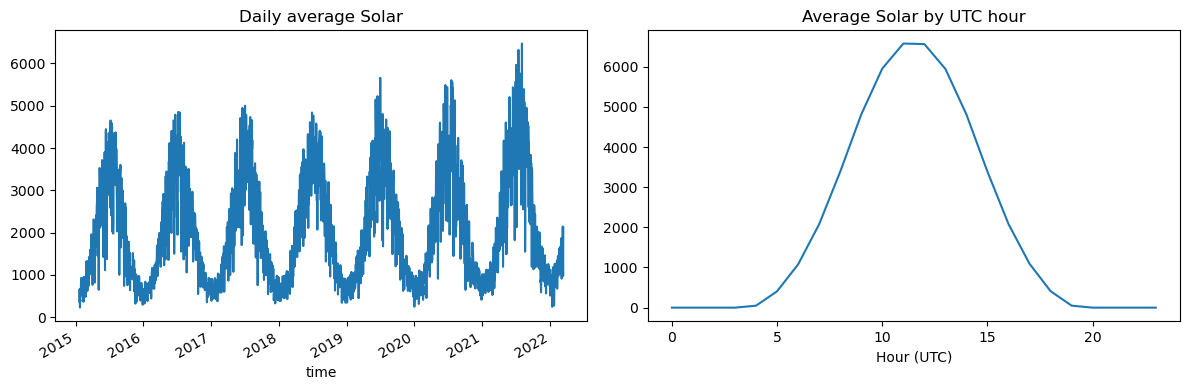

In [179]:
# Analyze trend and seasonality
solar = train_clean["Solar"]
solar_hours = solar.resample("D").count()
solar_daily = solar.resample("D").mean().where(solar_hours >= 12).dropna()
solar_hourly = solar.groupby(solar.index.hour).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

solar_daily.plot(ax=axes[0], title="Daily average Solar")
solar_hourly.plot(ax=axes[1], title="Average Solar by UTC hour")
axes[1].set_xlabel("Hour (UTC)")

plt.tight_layout()
plt.show()

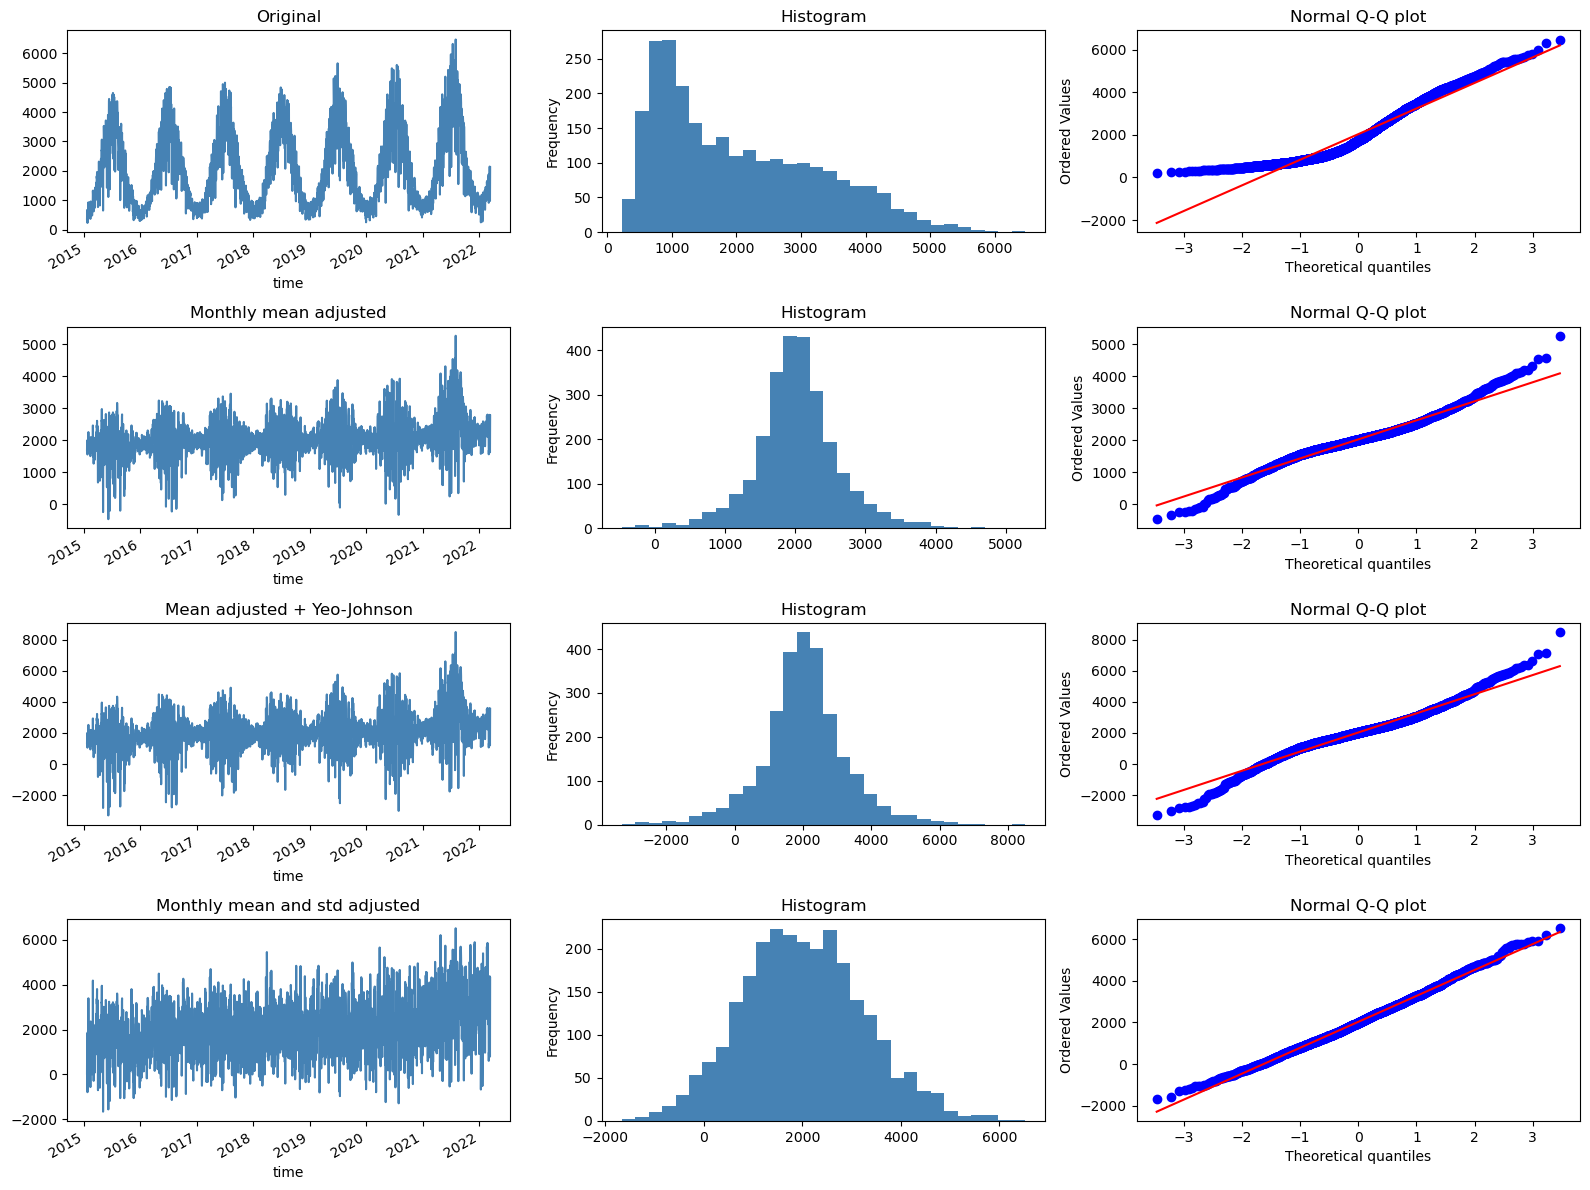

,Transformation,Skewness,Kurtosis
0,Normal,0.00,3.00
1,Original,0.69,2.54
2,Monthly mean adjusted,0.11,5.01
3,Mean adjusted + Yeo-Johnson,-0.04,4.99
4,Monthly mean and std adjusted,0.20,2.97


In [180]:
# Original daily solar generation
solar_clean = solar_daily.dropna()
monthly = solar_clean.groupby(solar_clean.index.month)

overall_mean = solar_clean.mean()
overall_std = solar_clean.std()

# Remove monthly means, then restore the original average level
solar_centered = solar_clean - monthly.transform("mean")
solar_deseason = solar_centered + overall_mean

# Alternative 1: Apply Yeo-Johnson to the centered deviations
transformed = PowerTransformer(method="yeo-johnson").fit_transform(
    solar_centered.to_frame()
)
solar_yj = pd.Series(transformed.flatten(), index=solar_clean.index)

# Alternative 2: Adjust seasonal variability
solar_standardized = solar_centered / monthly.transform("std")

# Display both alternatives on the original numerical scale
solar_comparisons = {
    "Original": solar_clean,
    "Monthly mean adjusted": solar_deseason,
    "Mean adjusted + Yeo-Johnson": solar_yj * overall_std + overall_mean,
    "Monthly mean and std adjusted": solar_standardized * overall_std + overall_mean
}

fig, axes = plt.subplots(4, 3, figsize=(16, 12))

for i, (name, values) in enumerate(solar_comparisons.items()):
    values.plot(
        ax=axes[i, 0], title=name, color="steelblue"
    )
    values.plot.hist(
        bins=30, ax=axes[i, 1], title="Histogram", color="steelblue"
    )
    stats.probplot(values, dist="norm", plot=axes[i, 2])
    axes[i, 2].set_title("Normal Q-Q plot")

plt.tight_layout()
plt.show()

# Compare skewness and ordinary kurtosis
results = [["Normal", 0, 3]]

for name, values in solar_comparisons.items():
    results.append([name, values.skew(), values.kurt() + 3])

solar_summary = pd.DataFrame(
    results, columns=["Transformation", "Skewness", "Kurtosis"]
)
display(solar_summary.round(2))

Removing monthly means adjusts seasonal differences in average solar generation, but summer fluctuations can still be larger than winter fluctuations. Dividing the centered values by their monthly standard deviations gives each month a comparable spread. This can reduce the heavy tails caused by combining months with different variability and bring the overall distribution closer to normal. 

### Q2 finding summary

**1. Trend and Seasonality**

Strong annual seasonality, with recurring peaks in summer and troughs in winter. Longer daylight hours and stronger sunlight during summer increase solar. A gradual upward trend over time, potentially reflecting increased solar generation capacity.

**2. Distribution and Normality**

The original not normally distributed and exhibits positive skewness. Partly due to seasonality: many winter days have relatively low generation, while summer days can have substantially higher generation. Weather variability also contributes.

**3. Deseasonalization**

Removing monthly averages reduces the differences between s&w generation, distribution more symmetric. Deseasonalization does not necessarily produce a normal distribution because short-term weather fluctuations, extreme observations, and long-term trends remain. 

**Conclusion**

Solar has clear annual seasonality and a non-normal distribution. Deseasonalization addresses systematic monthly differences but cannot guarantee normality, as remaining deviations in the Q-Q plots may indicate.

## Q3: Hourly pumped storage properties

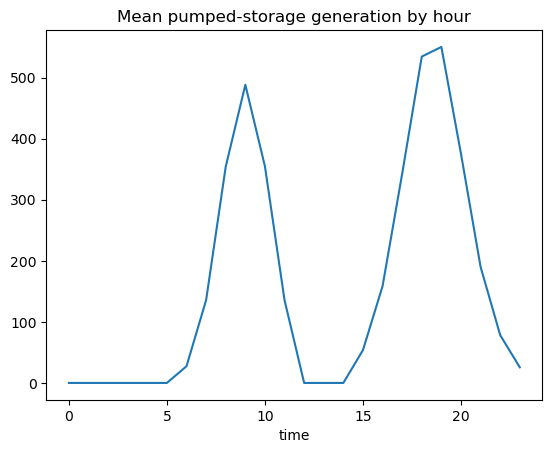

Peak before noon: 9
Peak from noon onward: 19


In [181]:
pumped = train_clean["Pumped_Storage"]
hourly_mean = pumped.groupby(pumped.index.hour).mean()

hourly_mean.plot(title="Mean pumped-storage generation by hour")
plt.show()

print("Peak before noon:", hourly_mean.loc[:11].idxmax())
print("Peak from noon onward:", hourly_mean.loc[12:].idxmax())

### Q3 finding summary

**1. Intraday Pattern**

Pumped storage shows two clear generation peaks, around 9 am and 7 pm (high-demand hours), with the evening peak generally higher. Generation is relatively low overnight and around midday. 

**2. Zero Generation and Variability**

Frequent zero-generation periods and high variability => it operates intermittently not providing constant electricity generation.

**3. Economic Interpretation**

Consumes electricity to pump water when prices are low and generates electricity when prices are high.

- Morning: Higher demand may encourage pumped-storage generation.

- Midday: Strong Solar generation can increase electricity supply and lower prices, reducing the need for pumped-storage generation and potentially creating opportunities for pumping.

- Evening: Solar generation declines while demand remains relatively high, increasing the need for flexible generation from pumped storage.

**Conclusion**

Pumped storage exhibits a clear intraday pattern, consistent with its role as a flexible energy-storage resource that helps balance electricity supply and demand.

# Part 2

## 1. Construct target

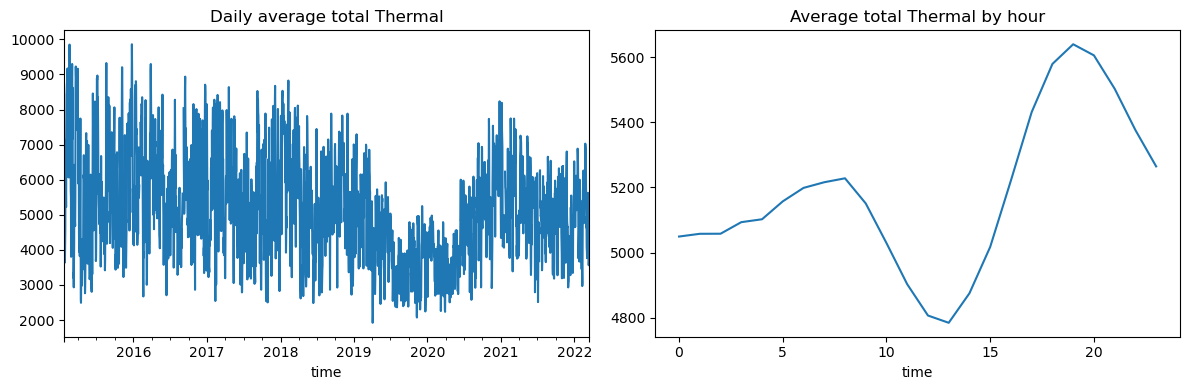

Target components: ['Thermal_Methane', 'Thermal_Oil', 'Thermal_Lignite', 'Thermal_Hard_Coal', 'Thermal_Biomass']
Non-missing development targets: 59167 in 62630
Non-missing test targets: 14475 in 15778


In [182]:
thermal_cols = [col for col in train_clean.columns if col.startswith("Thermal_")]
y_dev = train_clean[thermal_cols].sum(axis = 1, min_count = len(thermal_cols))
y_holdout = test_clean[thermal_cols].sum(axis = 1, min_count = len(thermal_cols))


fig, axes = plt.subplots(1, 2, figsize = (12, 4))
y_dev.resample("D").mean().plot(ax = axes[0], title = "Daily average total Thermal")
y_dev.groupby(y_dev.index.hour).mean().plot(ax = axes[1], title="Average total Thermal by hour")
plt.tight_layout()
plt.show()

print("Target components:", thermal_cols)
print("Non-missing development targets:", y_dev.notna().sum(), "in", len(y_dev))
print("Non-missing test targets:", y_holdout.notna().sum(), "in", len(y_holdout))

In [183]:
from sklearn.feature_selection import mutual_info_regression

# 1. Prepare predictors and target
corr_data = train_clean.drop(columns=thermal_cols).copy()
corr_data["Thermal"] = y_dev

# 2. Daily averages: require at least 12 valid hours per column
daily_counts = corr_data.resample("D").count()
daily_data = corr_data.resample("D").mean().where(daily_counts >= 12)

# 3. Complete observations for hourly dependence checks
hourly_data = corr_data.dropna()
X_corr = hourly_data.drop(columns="Thermal")
y_corr = hourly_data["Thermal"]

dependence = pd.DataFrame({
    "Hourly Pearson": X_corr.corrwith(y_corr),
    "Hourly Spearman": X_corr.corrwith(y_corr, method="spearman"),
    "Daily Spearman": daily_data.corr(method="spearman")["Thermal"].drop("Thermal"),
    "Hourly MI": mutual_info_regression(
        X_corr, y_corr, random_state=42
    )
}, index=X_corr.columns)

display(dependence.sort_values("Hourly MI", ascending=False).round(3))

# 4. Pearson correlations between predictors
display(X_corr.corr().round(2))

,Hourly Pearson,Hourly Spearman,Daily Spearman,Hourly MI
Wind_Onshore,-0.655,-0.667,-0.654,0.332
Wind_Offshore,-0.436,-0.440,-0.465,0.140
Waste,-0.202,-0.184,-0.212,0.081
Geothermal,-0.224,-0.202,-0.226,0.067
Hydro_Run_of_River,0.098,0.111,0.103,0.056
Nuclear,0.007,0.030,0.036,0.054
Solar,-0.170,-0.139,-0.177,0.022
Hydro_Reservoir,0.025,0.036,0.050,0.019
Pumped_Storage,0.115,0.094,0.137,0.007


,Wind_Offshore,Waste,Pumped_Storage,Solar,Wind_Onshore,Nuclear,Hydro_Run_of_River,Hydro_Reservoir,Geothermal
Wind_Offshore,1.00,0.28,-0.04,-0.06,0.48,-0.04,-0.04,-0.13,0.29
Waste,0.28,1.00,-0.06,-0.03,0.12,-0.06,-0.10,-0.20,0.51
Pumped_Storage,-0.04,-0.06,1.00,0.01,-0.00,0.02,0.03,0.04,-0.08
Solar,-0.06,-0.03,0.01,1.00,-0.09,-0.05,-0.05,0.05,0.03
Wind_Onshore,0.48,0.12,-0.00,-0.09,1.00,-0.01,0.05,-0.04,0.07
Nuclear,-0.04,-0.06,0.02,-0.05,-0.01,1.00,0.09,0.05,0.11
Hydro_Run_of_River,-0.04,-0.10,0.03,-0.05,0.05,0.09,1.00,0.40,-0.11
Hydro_Reservoir,-0.13,-0.20,0.04,0.05,-0.04,0.05,0.40,1.00,-0.28
Geothermal,0.29,0.51,-0.08,0.03,0.07,0.11,-0.11,-0.28,1.00


Thermal components were excluded from the predictors to avoid target leakage. Pearson correlation measures linear association, Spearman captures monotonic relationships, and mutual information captures broader nonlinear dependence. Daily correlations were also examined using averages based on at least 12 valid hours. Predictor correlations were checked for potential linear redundancy. 

## 2. Construct features

In [184]:
sources = pd.concat([train_clean, test_clean]).sort_index()
features = sources[["Solar", "Wind_Onshore", "Wind_Offshore"]].copy()

for col in ["Pumped_Storage", "Hydro_Run_of_River"]:
    features[f"{col}_lag1"] = sources[col].shift(1)  # previous hour only

hours = features.index.hour
for k in [1, 2]:
    features[f"hour_sin{k}"] = np.sin(2 * np.pi * k * hours / 24) # 24-hour cycle
    features[f"hour_cos{k}"] = np.cos(2 * np.pi * k * hours / 24) # 12-hour cycle

year_days = np.where(features.index.is_leap_year, 366, 365)
annual_phase = (features.index.dayofyear - 1) / year_days
features["year_sin"] = np.sin(2 * np.pi * annual_phase)
features["year_cos"] = np.cos(2 * np.pi * annual_phase)

# For imputation only, will be dropped later
features["month"] = features.index.month  
features["hour"] = features.index.hour    

features["trend"] = (
    (features.index - features.index[0]).total_seconds()
    / (365.25 * 24 * 3600)
)

# features["is_weekend"] = (features.index.dayofweek >= 5).astype(int)

X_dev = features.loc[train_clean.index].copy()
X_holdout = features.loc[test_clean.index].copy()
print("Feature columns:", features.columns.to_list())

Feature columns: ['Solar', 'Wind_Onshore', 'Wind_Offshore', 'Pumped_Storage_lag1', 'Hydro_Run_of_River_lag1', 'hour_sin1', 'hour_cos1', 'hour_sin2', 'hour_cos2', 'year_sin', 'year_cos', 'month', 'hour', 'trend']


## 3. Impute features

In [ ]:
def impute_pair(train_features, other_features):
    X_train = train_features.copy()
    X_other = other_features.copy()

    # If need to ffill some columns
    # ffill_cols = ["Pumped_Storage_lag1", "Hydro_Run_of_River_lag1"]
    # X_train[ffill_cols] = X_train[ffill_cols].ffill(limit=3)
    # X_other[ffill_cols] = X_other[ffill_cols].ffill(limit=3)

    rules = {
        "Solar": ["month", "hour"],
        "Wind_Onshore": ["month", "hour"],
        "Wind_Offshore": ["month"],
        "Hydro_Run_of_River_lag1": ["month"],
        "Pumped_Storage_lag1": ["hour"],
    }

    for col, group_keys in rules.items():
        group_mean = train_features.groupby(group_keys)[col].mean().rename("group_mean")
        overall_mean = train_features[col].mean()
        for frame in (X_train, X_other):
            by_group = frame.join(group_mean, on = group_keys)["group_mean"]
            frame[col] = frame[col].fillna(by_group).fillna(overall_mean)

    return (X_train.drop(columns = ["month", "hour"]),
            X_other.drop(columns = ["month", "hour"]))

## 4. Model comparison with expanding-window cross validation

In [ ]:
models = {
    "OLS": LinearRegression(),

    "Ridge": Ridge(alpha=10),

    "Random forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=50,
        max_features=0.8,       # Consider 80% of features at each split
        n_jobs=-1,              # Use all available CPU cores
        random_state=42,
    ),

    "XGBoost": xgb.XGBRegressor(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,          # Sample 80% of training rows per tree
        colsample_bytree=0.8,   # Sample 80% of features per tree
        min_child_weight=10,   # Discourage small leaves
        reg_lambda=1,          # L2 penalty on leaf weights; already the default
        n_jobs=-1,
        random_state=42,
    ),

    # "LightGBM": lgb.LGBMRegressor(
    #     n_estimators=150,
    #     num_leaves=8,           # Controls tree complexity
    #     learning_rate=0.03,
    #     random_state=42,
    #     importance_type="gain",
    # ),
}


cv = TimeSeriesSplit(n_splits = 3, test_size = 24 * 365)
cv_rows = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_dev), start = 1):

    X_train, X_val = impute_pair(X_dev.iloc[train_idx], X_dev.iloc[val_idx])
    y_train, y_val = y_dev.iloc[train_idx], y_dev.iloc[val_idx]
    train_valid, val_valid = y_train.notna(), y_val.notna()

    for name, model in models.items():
        model_train = X_train.loc[train_valid]
        model_val = X_val.loc[val_valid]

        if name in ["OLS", "Ridge"]:
            scaler = StandardScaler()
            model_train = scaler.fit_transform(model_train)
            model_val = scaler.transform(model_val)

        model.fit(model_train, y_train.loc[train_valid])
        val_pred = model.predict(model_val)

        cv_rows.append({
            "Fold": fold,
            "Model": name,
            "RMSE": root_mean_squared_error(y_val.loc[val_valid], val_pred),
            "MAE": mean_absolute_error(y_val.loc[val_valid], val_pred),
            "R2": r2_score(y_val.loc[val_valid], val_pred),
        })

    print(f"Fold {fold}: validation {X_val.index.min().date()} to {X_val.index.max().date()}")

Fold 1: validation 2019-03-15 to 2020-03-14
Fold 2: validation 2020-03-14 to 2021-03-14
Fold 3: validation 2021-03-14 to 2022-03-14


### Model evaluation

In [187]:
cv_results = pd.DataFrame(cv_rows)
display(cv_results.set_index(["Fold", "Model"]).round(2))

cv_summary = (cv_results.groupby("Model")[["RMSE", "MAE", "R2"]].mean().sort_values("RMSE"))
display(cv_summary.round(2))

best_name = cv_summary.index[0]
print("Selected model:", best_name)

RMSE      MAE    R2
Fold Model                                
1    OLS            1517.60  1256.59 -1.39
     Ridge          1517.46  1256.57 -1.39
     Random forest  1787.41  1597.17 -2.31
     XGBoost        1471.68  1315.36 -1.25
2    OLS            1462.92  1243.79 -0.10
     Ridge          1462.63  1243.52 -0.10
     Random forest  1675.27  1319.34 -0.44
     XGBoost        1555.24  1239.96 -0.25
3    OLS            1066.26   887.58  0.10
     Ridge          1066.04   887.39  0.10
     Random forest   986.64   785.48  0.23
     XGBoost         957.22   811.01  0.27

,RMSE,MAE,R2
Model,,,
XGBoost,1328.05,1122.11,-0.41
Ridge,1348.71,1129.16,-0.46
OLS,1348.92,1129.32,-0.46
Random forest,1483.11,1234.00,-0.84


Selected model: XGBoost


## 5. Refit on development and feature importance

Wind_Onshore               0.347
trend                      0.135
year_cos                   0.128
Wind_Offshore              0.101
hour_sin1                  0.053
Pumped_Storage_lag1        0.052
Solar                      0.049
Hydro_Run_of_River_lag1    0.046
hour_sin2                  0.028
hour_cos2                  0.025
hour_cos1                  0.021
year_sin                   0.015
dtype: float32

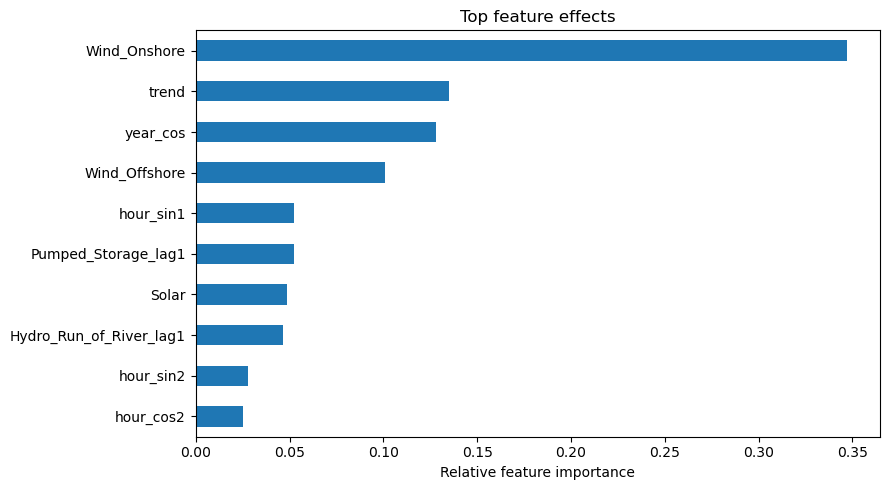

In [188]:
# Impute using development-set statistics
X_fit, X_test = impute_pair(X_dev, X_holdout)
fit_valid = y_dev.notna()

# OLS/Ridge: uncomment this scaling block
# scaler = StandardScaler().set_output(transform="pandas")
# scaler.fit(X_fit.loc[fit_valid])
# X_fit = scaler.transform(X_fit)
# X_test = scaler.transform(X_test)

# Refit the selected model
final_model = models[best_name]
final_model.fit(X_fit.loc[fit_valid], y_dev.loc[fit_valid])

# Tree models: comment out these two lines for OLS/Ridge
values = final_model.feature_importances_
importance_label = "Relative feature importance"

# OLS/Ridge: uncomment these two lines
# values = final_model.coef_
# importance_label = "Predicted Thermal change per 1 SD increase"

# Rank features by absolute effect or importance
importance = pd.Series(values, index=X_fit.columns)
importance = importance.loc[
    importance.abs().sort_values(ascending=False).index
]
display(importance.round(3))

# Plot the top 10 features
importance.head(10).sort_values().plot.barh(
    figsize=(9, 5), title="Top feature effects"
)
plt.xlabel(importance_label)
plt.tight_layout()
plt.show()

## 6. Heldout prediction

In [189]:
# Predict all test hours
test_predictions = pd.Series(
    final_model.predict(X_test), index=X_holdout.index
)

# Keep only hours with observed targets
actual = y_holdout.dropna()
predicted = test_predictions.loc[actual.index]
baseline = np.repeat(y_dev.mean(), len(actual))

# Calculate scores directly: baseline first, model second
final_scores = pd.DataFrame({
    "RMSE": [
        root_mean_squared_error(actual, baseline),
        root_mean_squared_error(actual, predicted),
    ],
    "MAE": [
        mean_absolute_error(actual, baseline),
        mean_absolute_error(actual, predicted),
    ],
    "R2": [
        r2_score(actual, baseline),
        r2_score(actual, predicted),
    ],
}, index=["Train Mean Baseline", best_name])

display(final_scores.round(3))

print("Scored hours:", len(actual), "in", len(y_holdout))
print("Excluded hours with missing Thermal target:", y_holdout.isna().sum())

,RMSE,MAE,R2
Train Mean Baseline,1283.860,1053.242,-0.166
XGBoost,561.912,447.842,0.777


Scored hours: 14475 in 15778
Excluded hours with missing Thermal target: 1303


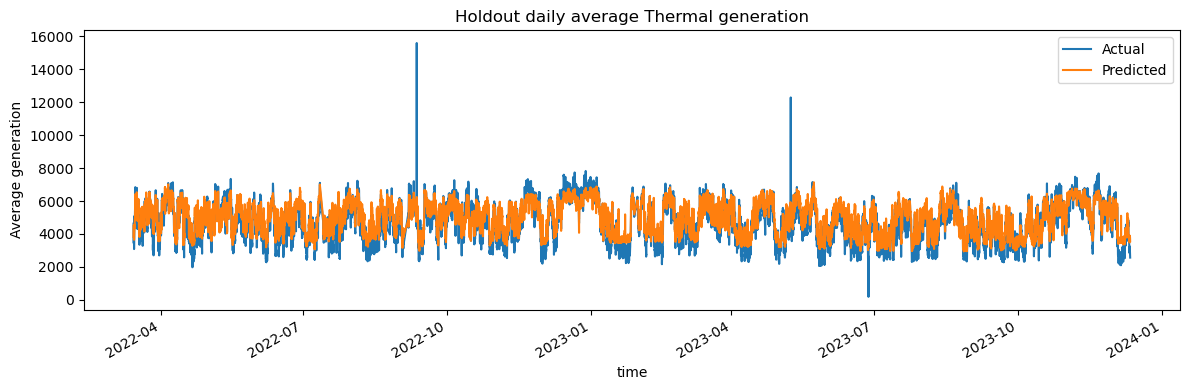

In [190]:
comparison = pd.DataFrame({"Actual": actual, "Predicted": predicted})
comparison.plot(
    figsize = (12, 4), title = "Holdout daily average Thermal generation"
)
plt.ylabel("Average generation")
plt.tight_layout()
plt.show()

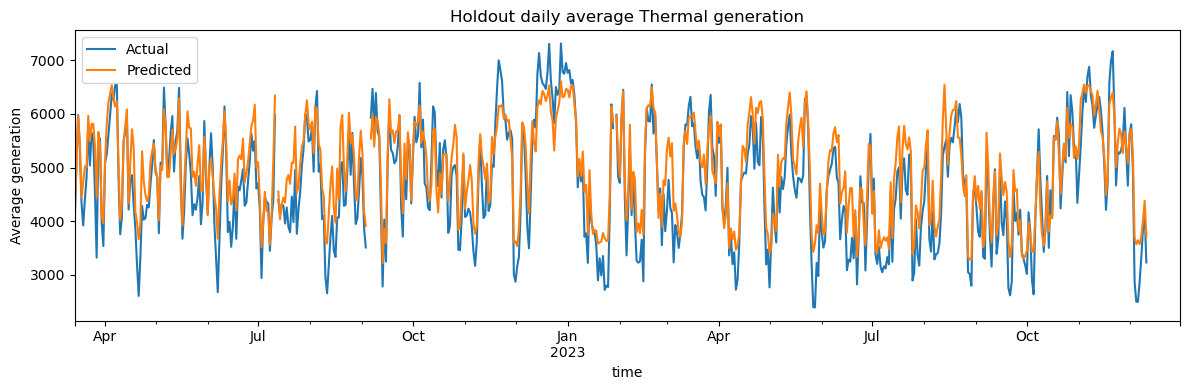

In [191]:
comparison = pd.DataFrame({"Actual": y_holdout, "Predicted": predicted})
comparison.resample("D").mean().plot(
    figsize = (12, 4), title = "Holdout daily average Thermal generation"
)
plt.ylabel("Average generation")
plt.tight_layout()
plt.show()